# 多模态 AIGC 图像生成 03：Stable Diffusion 详解

本篇对应讲义《03-StableDiffusion详解.pdf》，围绕四个主题整理：

1. Stable Diffusion 的相关概念、发展背景和特点；
2. 扩散模型的工作原理与 Stable Diffusion 的模型构成；
3. 文生图的完整处理流程；
4. 文生图、图生图和图像修复三类应用场景。

讲义中的宣传页和结束页已省略。

## 一、Stable Diffusion 简介

### 1. 相关概念

| 概念 | 含义 |
| --- | --- |
| Diffusion Model | 支持图像生成的扩散模型。DALL·E、Midjourney、Imagen、Stable Diffusion 等工具都建立在扩散模型或其相关技术之上。 |
| Latent Diffusion Model | 潜在扩散模型，在扩散模型基础上先把图像映射到更低维的潜空间，再进行扩散运算，以提高生成速度并降低计算资源和内存需求。 |
| Stable Diffusion | 简称 SD 模型，底层采用潜在扩散模型；名称来自研发公司 Stability AI。 |
| Stable Diffusion WebUI | 操作 Stable Diffusion 的网页端界面，用户可以通过界面控制模型出图，不必直接编写代码。 |

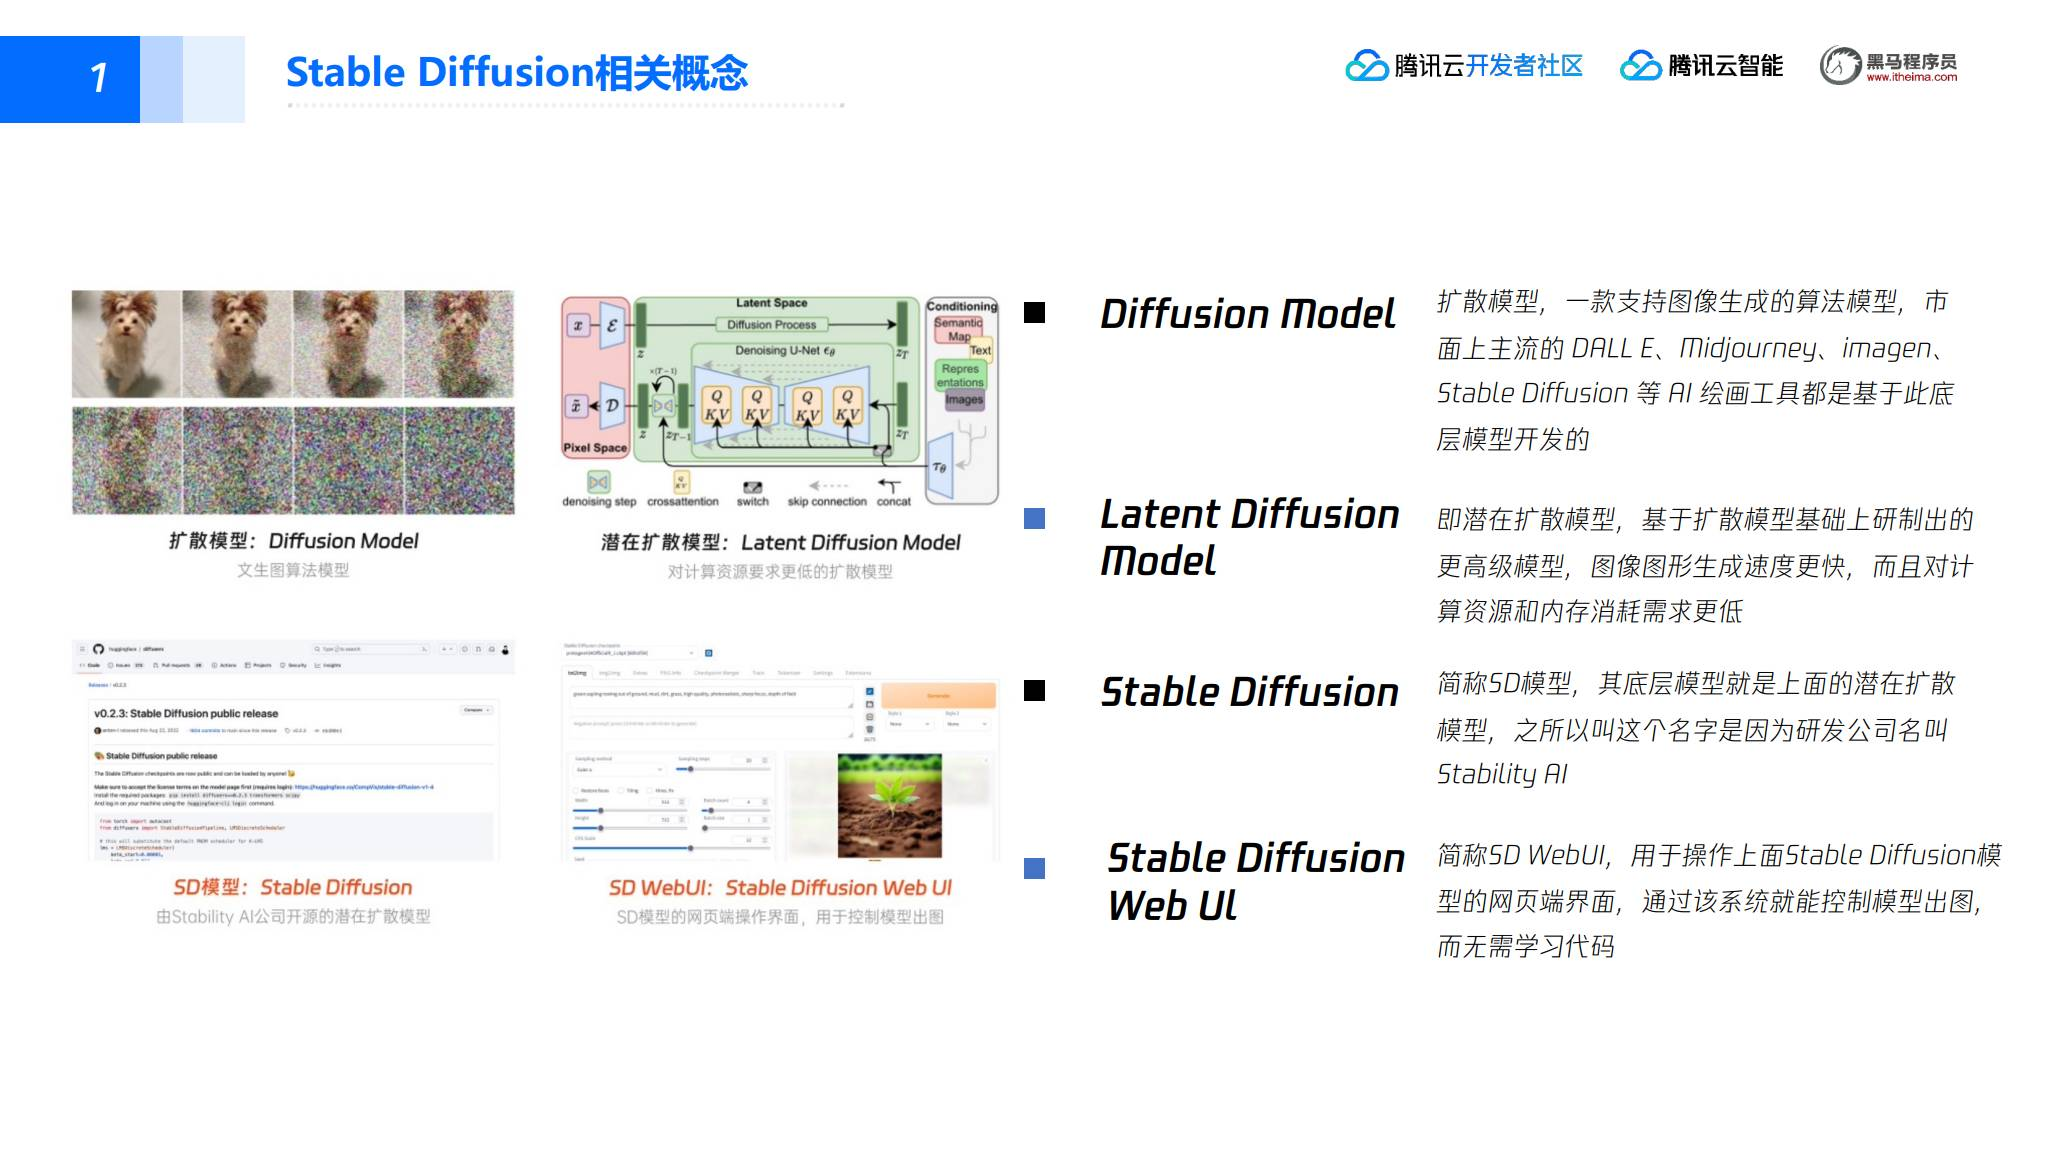

### 2. 发展背景

讲义给出的发展线索包括：

- Latent Diffusion Model 由慕尼黑大学 CompVis 机器学习研究小组与纽约 Runway 团队合作研发，目标是减少生成速度和资源消耗；
- 2022 年 7 月，Stable Diffusion 正式亮相；
- 2022 年 8 月 22 日，Stable Diffusion 正式开源；
- 讲义指出，Stable Diffusion 相比 Latent Diffusion 在生成准确性和支持的图像分辨率方面进一步增强；
- 该项目由 Stability AI、CompVis 和 Runway 团队合作开发，并获得了较高关注度。

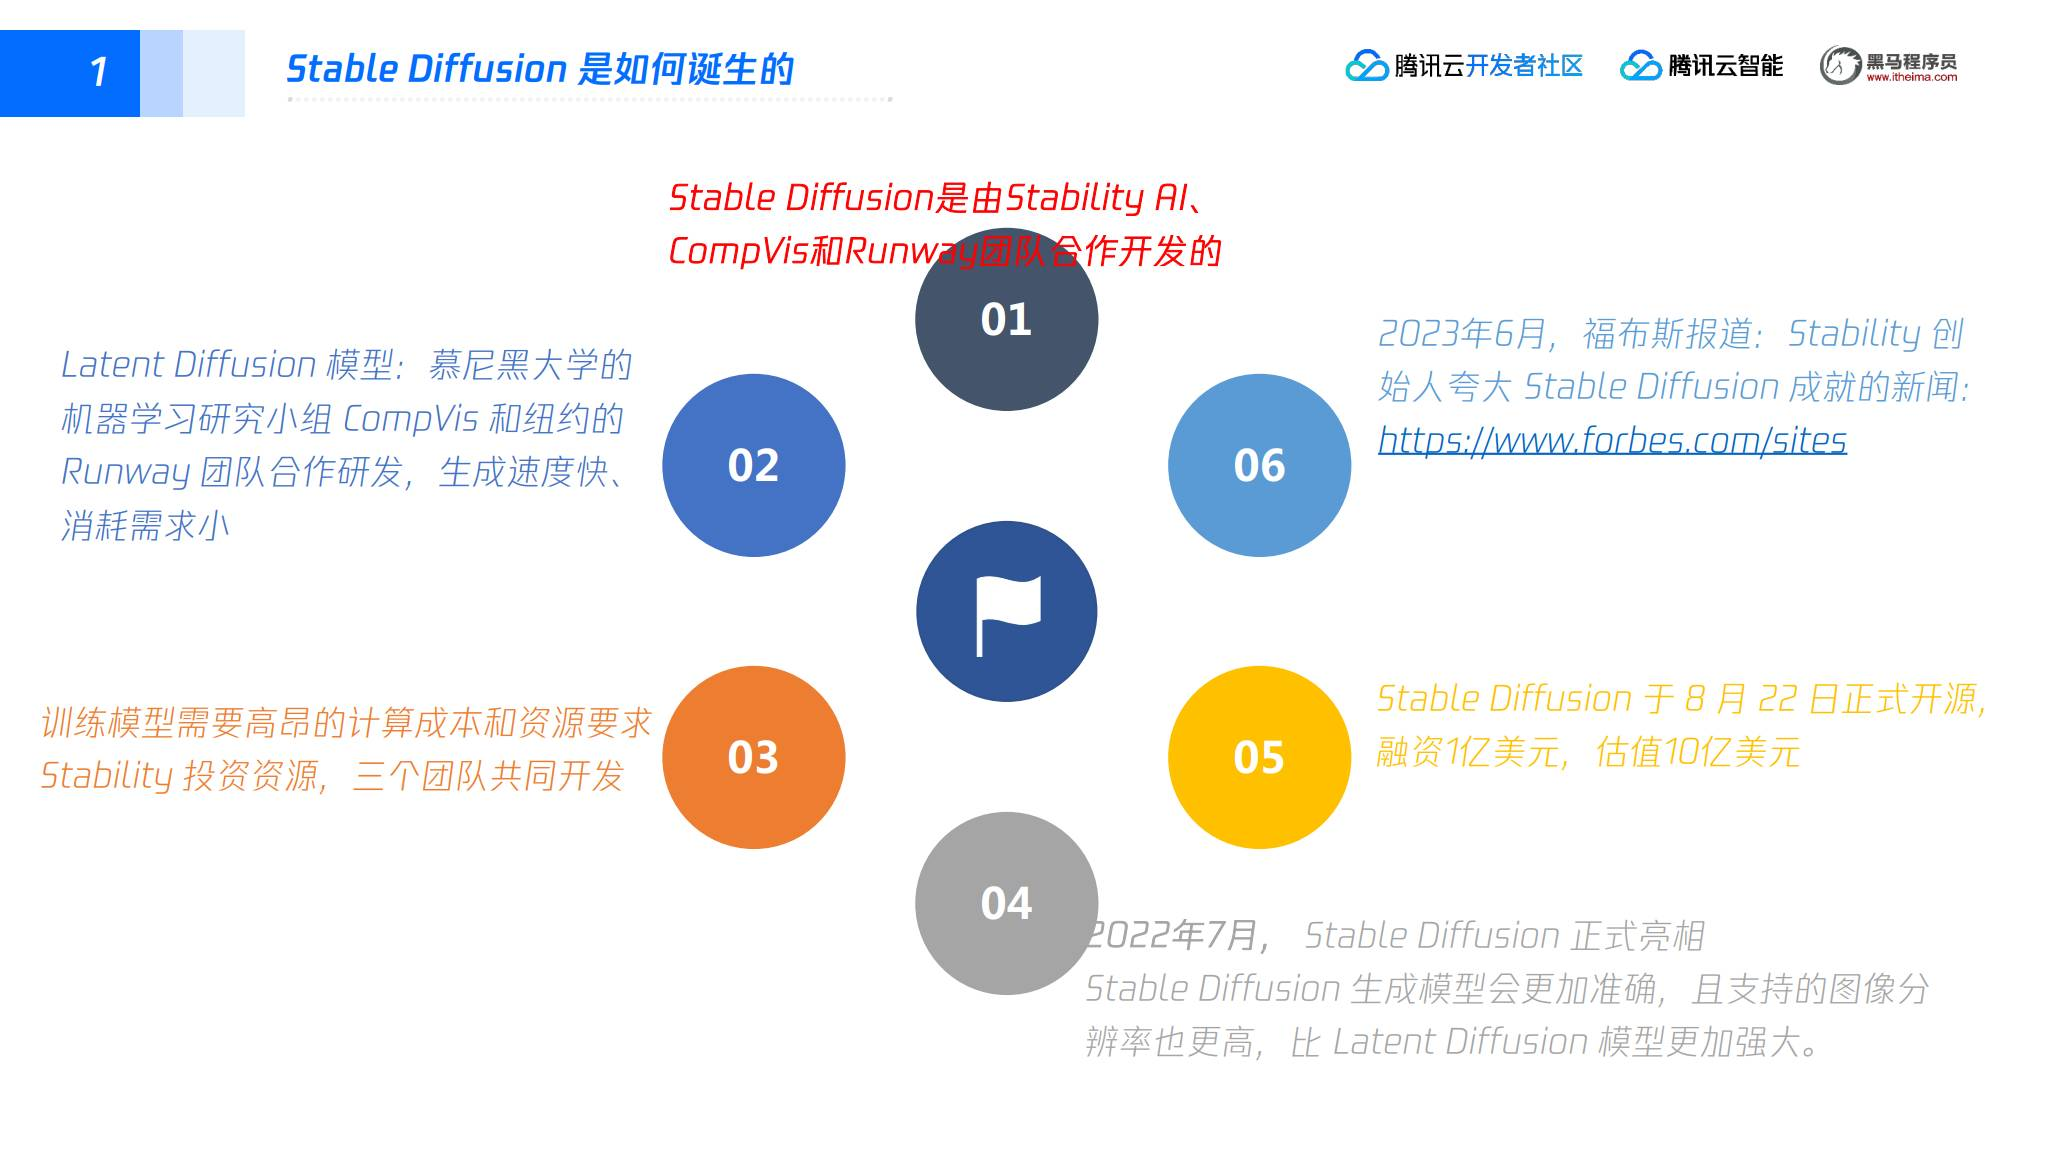

### 3. 主要特点

#### 可拓展性强

Stable Diffusion 公开论文和模型代码，便于学习、研究和二次创作。讲义列举其集成的扩展方向包括局部重绘、人物姿势控制、图像高清修复和线稿提取等，课程资料将其概括为 110 多项功能扩展。

#### 可控制图像分辨率

行业中常见的痛点是难以精准控制画面和分辨率。讲义以 ControlNet 和 UpScale 等插件为例，说明可以进一步控制构图、姿态和图像放大修复。

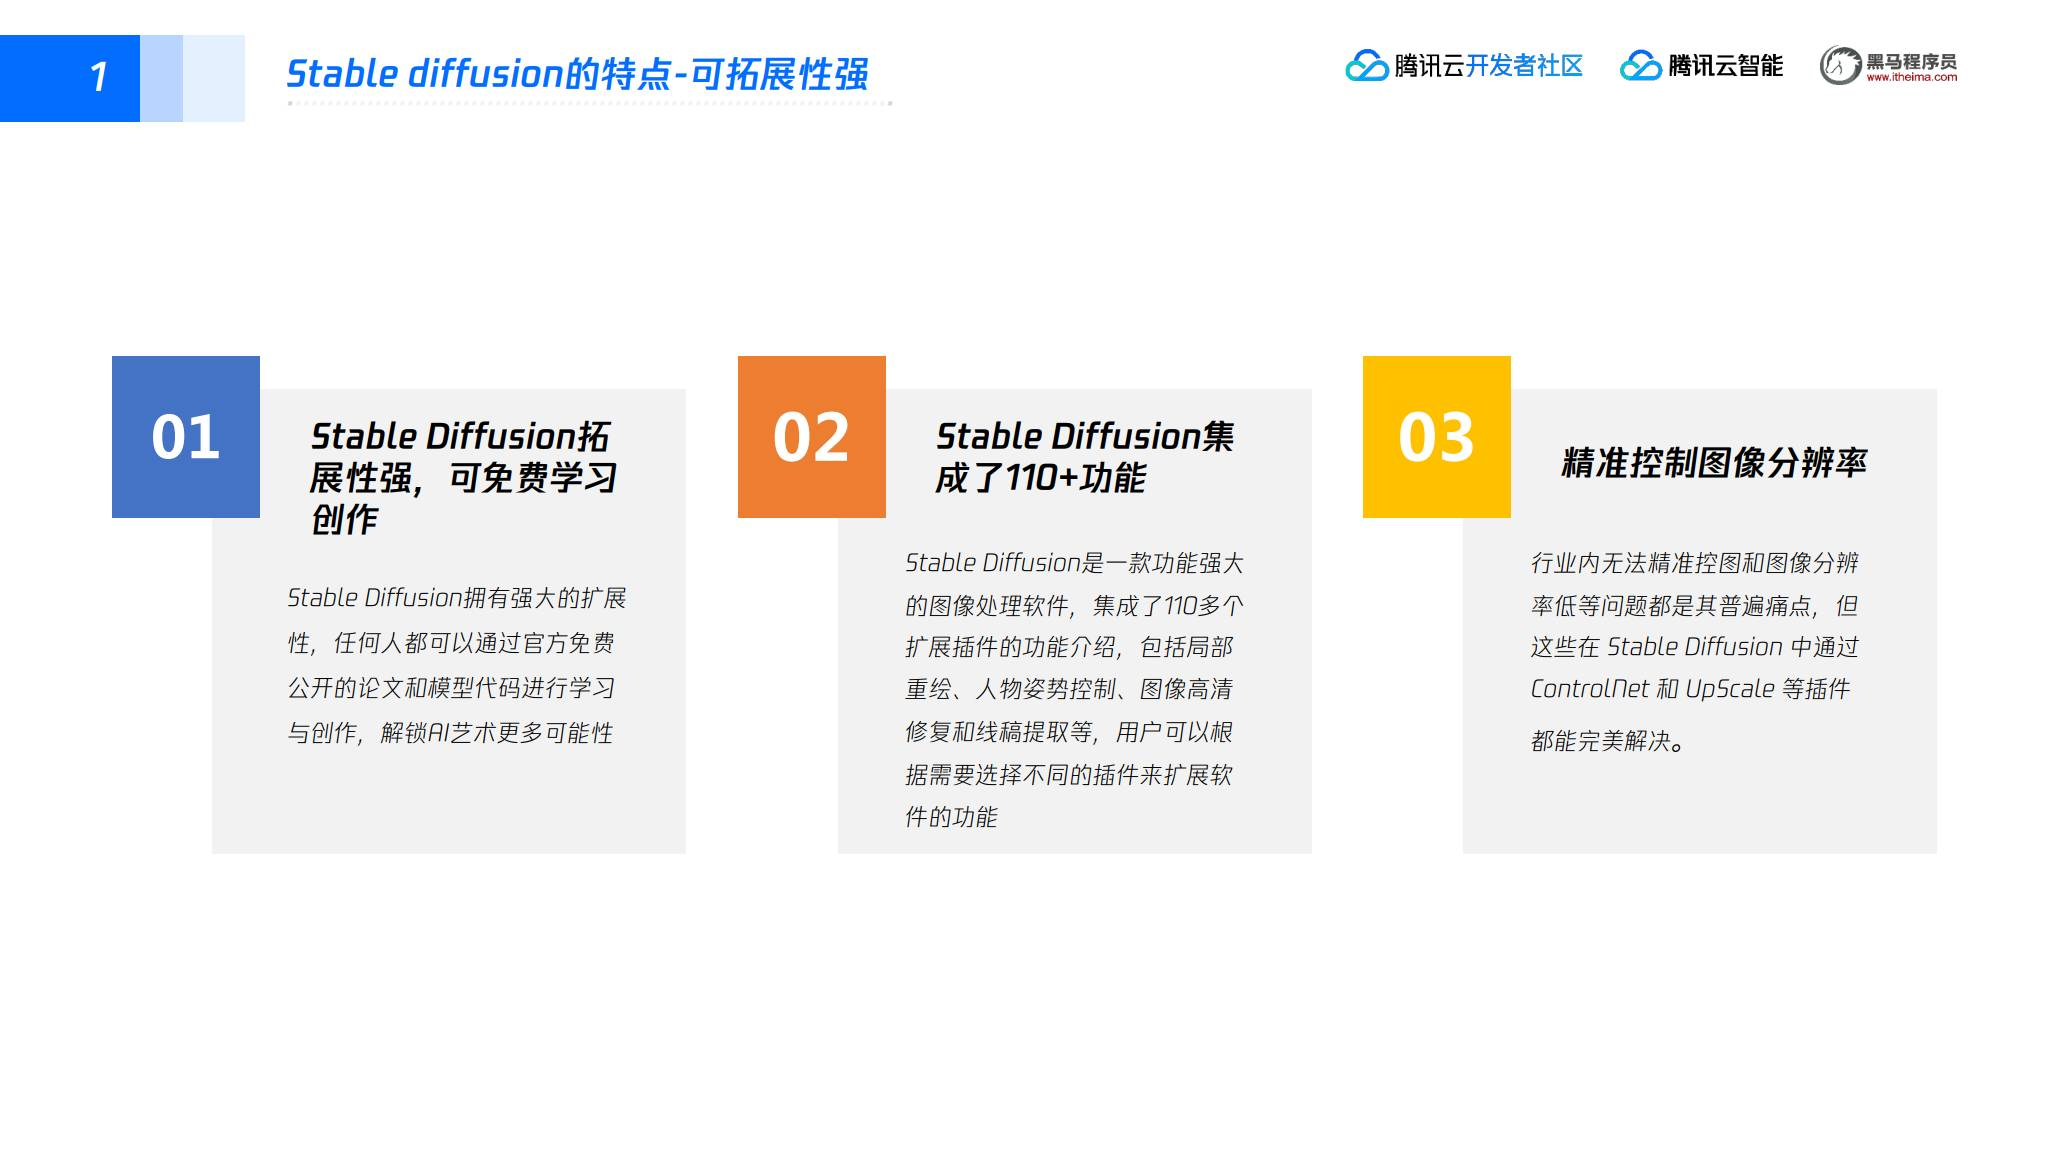

#### 本地部署，出图速度取决于硬件

在线商业绘画工具通常需要排队等待服务器响应，还会受到网络延迟和资源过载影响。Stable Diffusion 可以部署在本地，绘图效率主要由本地硬件决定；讲义以显卡算力充足时约 3 秒生成一张图作为速度示例。

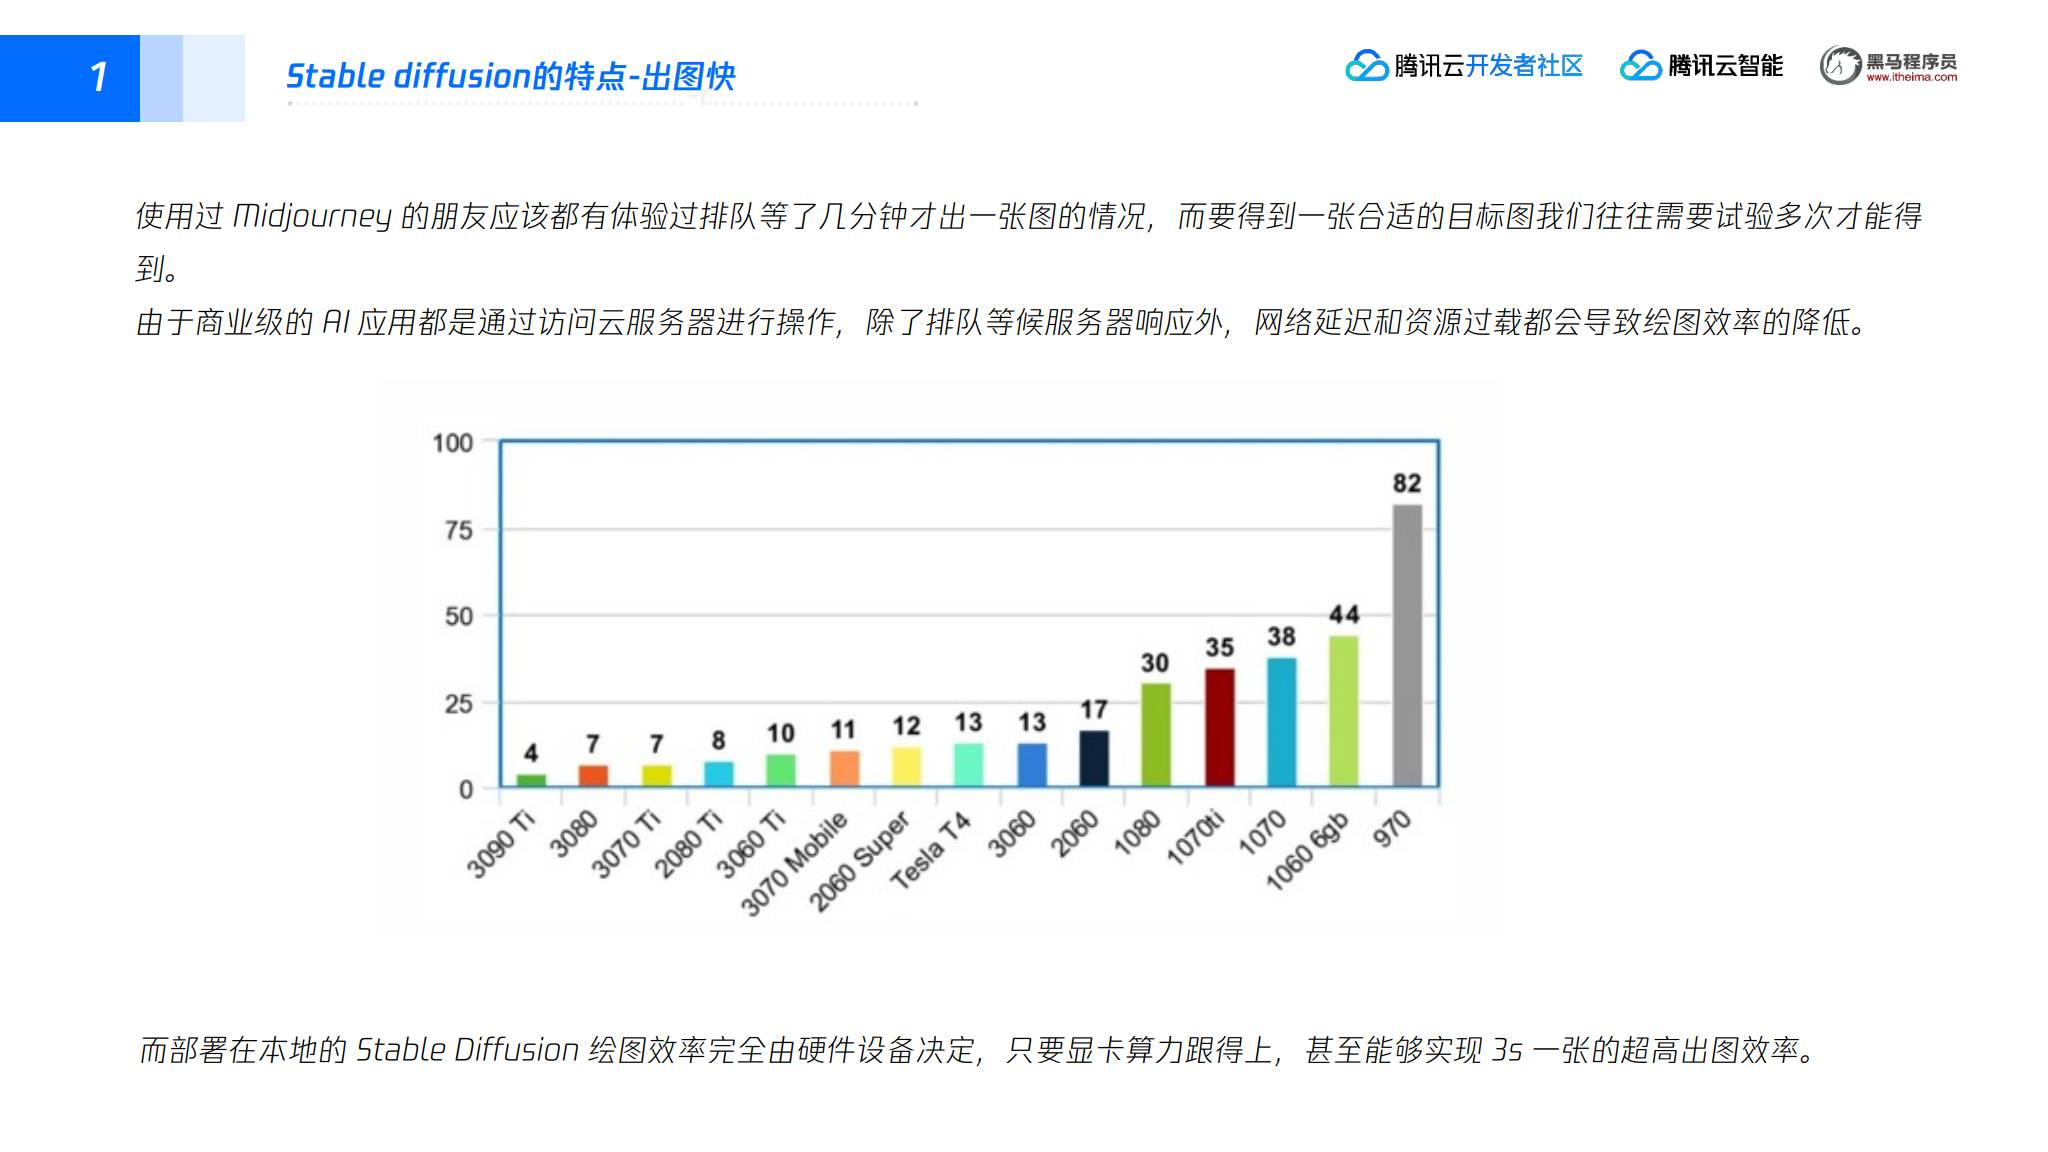

#### 数据在本地处理

Stable Diffusion 在本地完成绘图过程，用户的输入和生成结果不必默认上传到在线绘画平台，讲义据此强调其在数据安全方面的优势。

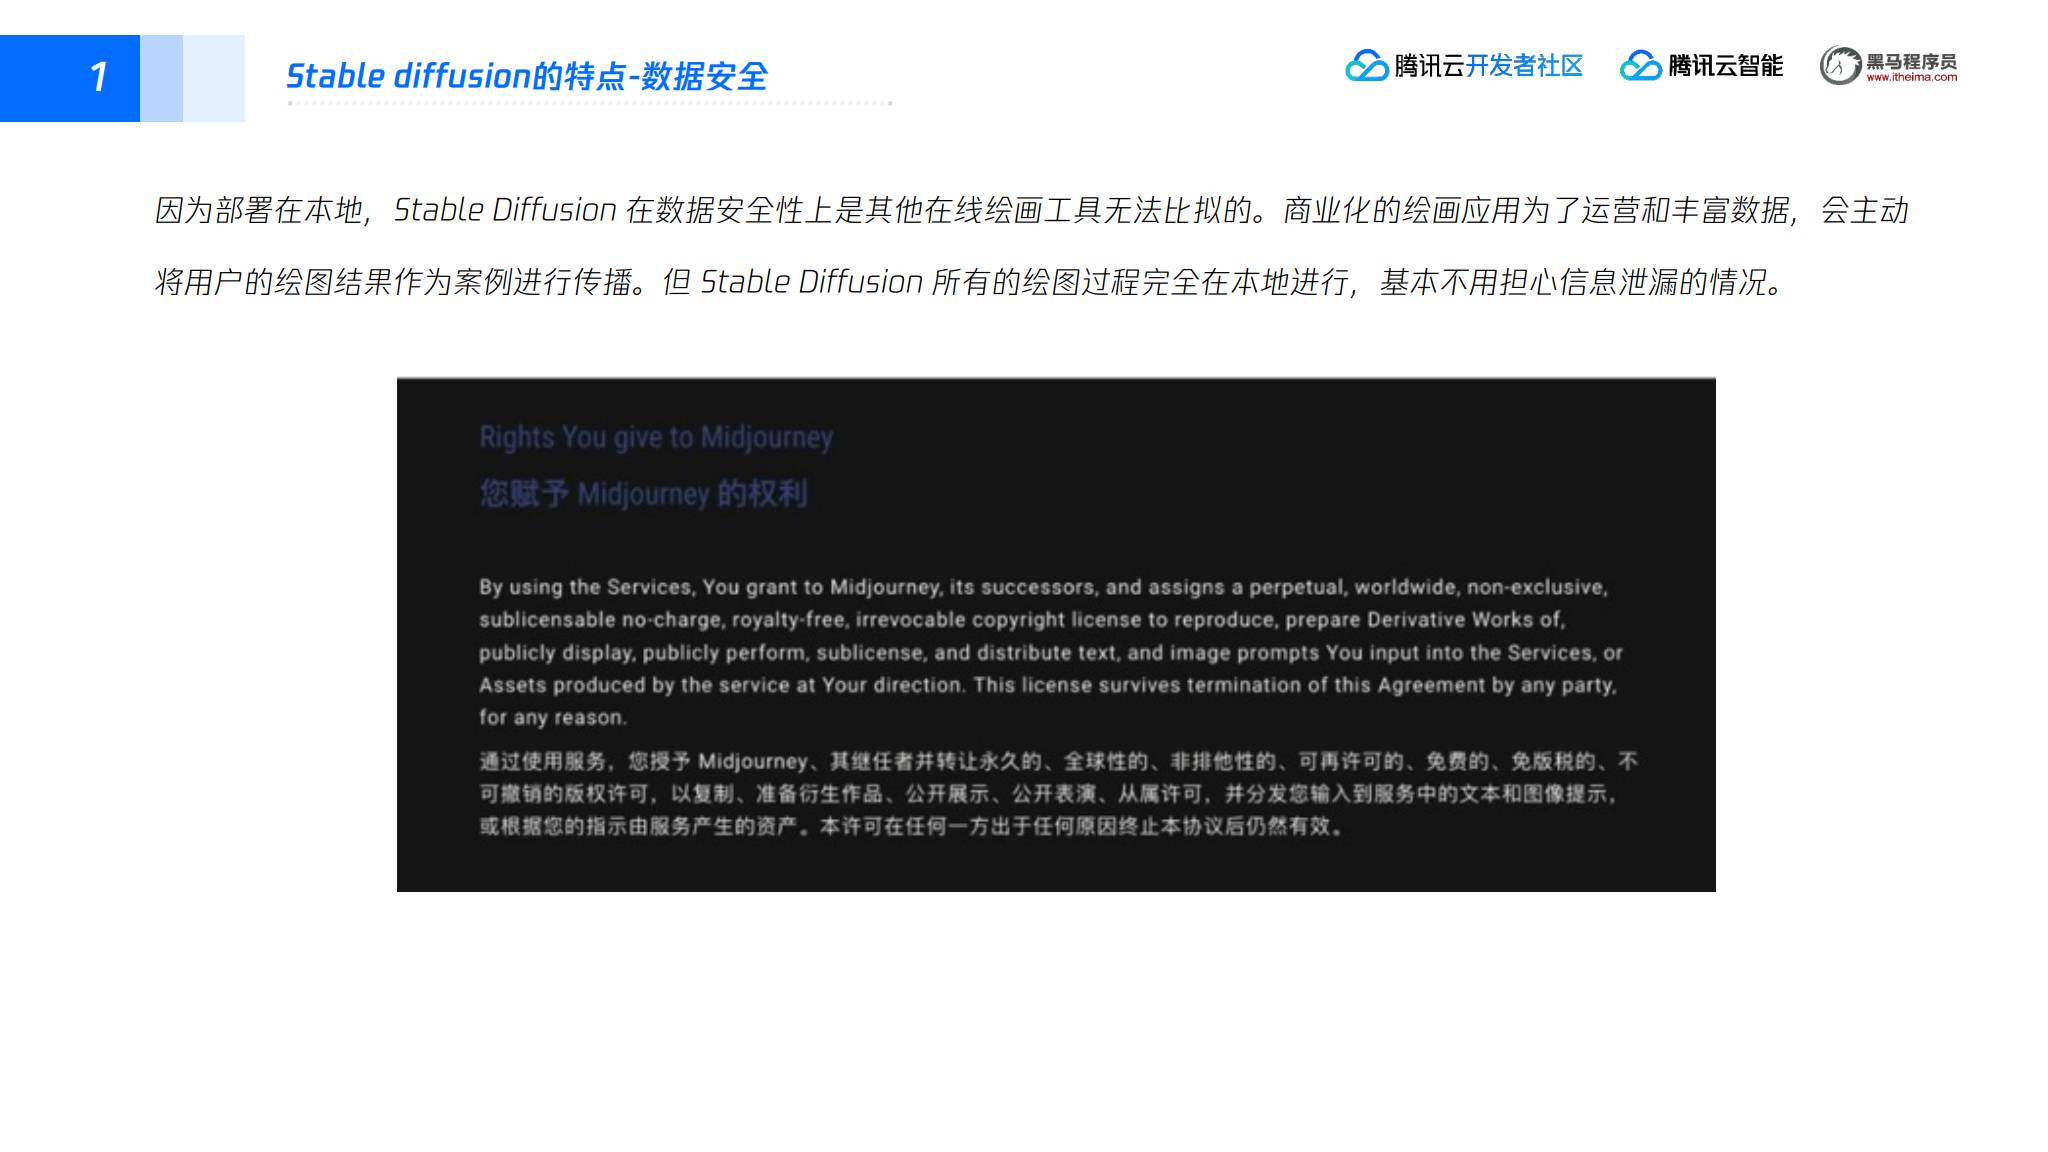

## 二、Stable Diffusion 的运行原理

### 1. 扩散模型的整体思路

扩散模型的运作过程可以理解为“逐步加噪，再逐步去噪”：

- **正向过程**：从原始图像 `x₀` 开始，逐步加入高斯噪声，得到 `x₁`、`x₂`，直到 `xₙ` 近似服从高斯分布。
- **反向过程**：随机生成一张高斯噪声图像，再一步步减少噪声，恢复出想要的图像。由于从 `t` 时刻一次跳回 `0` 时刻很困难，实际会先学习 `t` 与 `t-1` 的关系，再逐步向前推导。

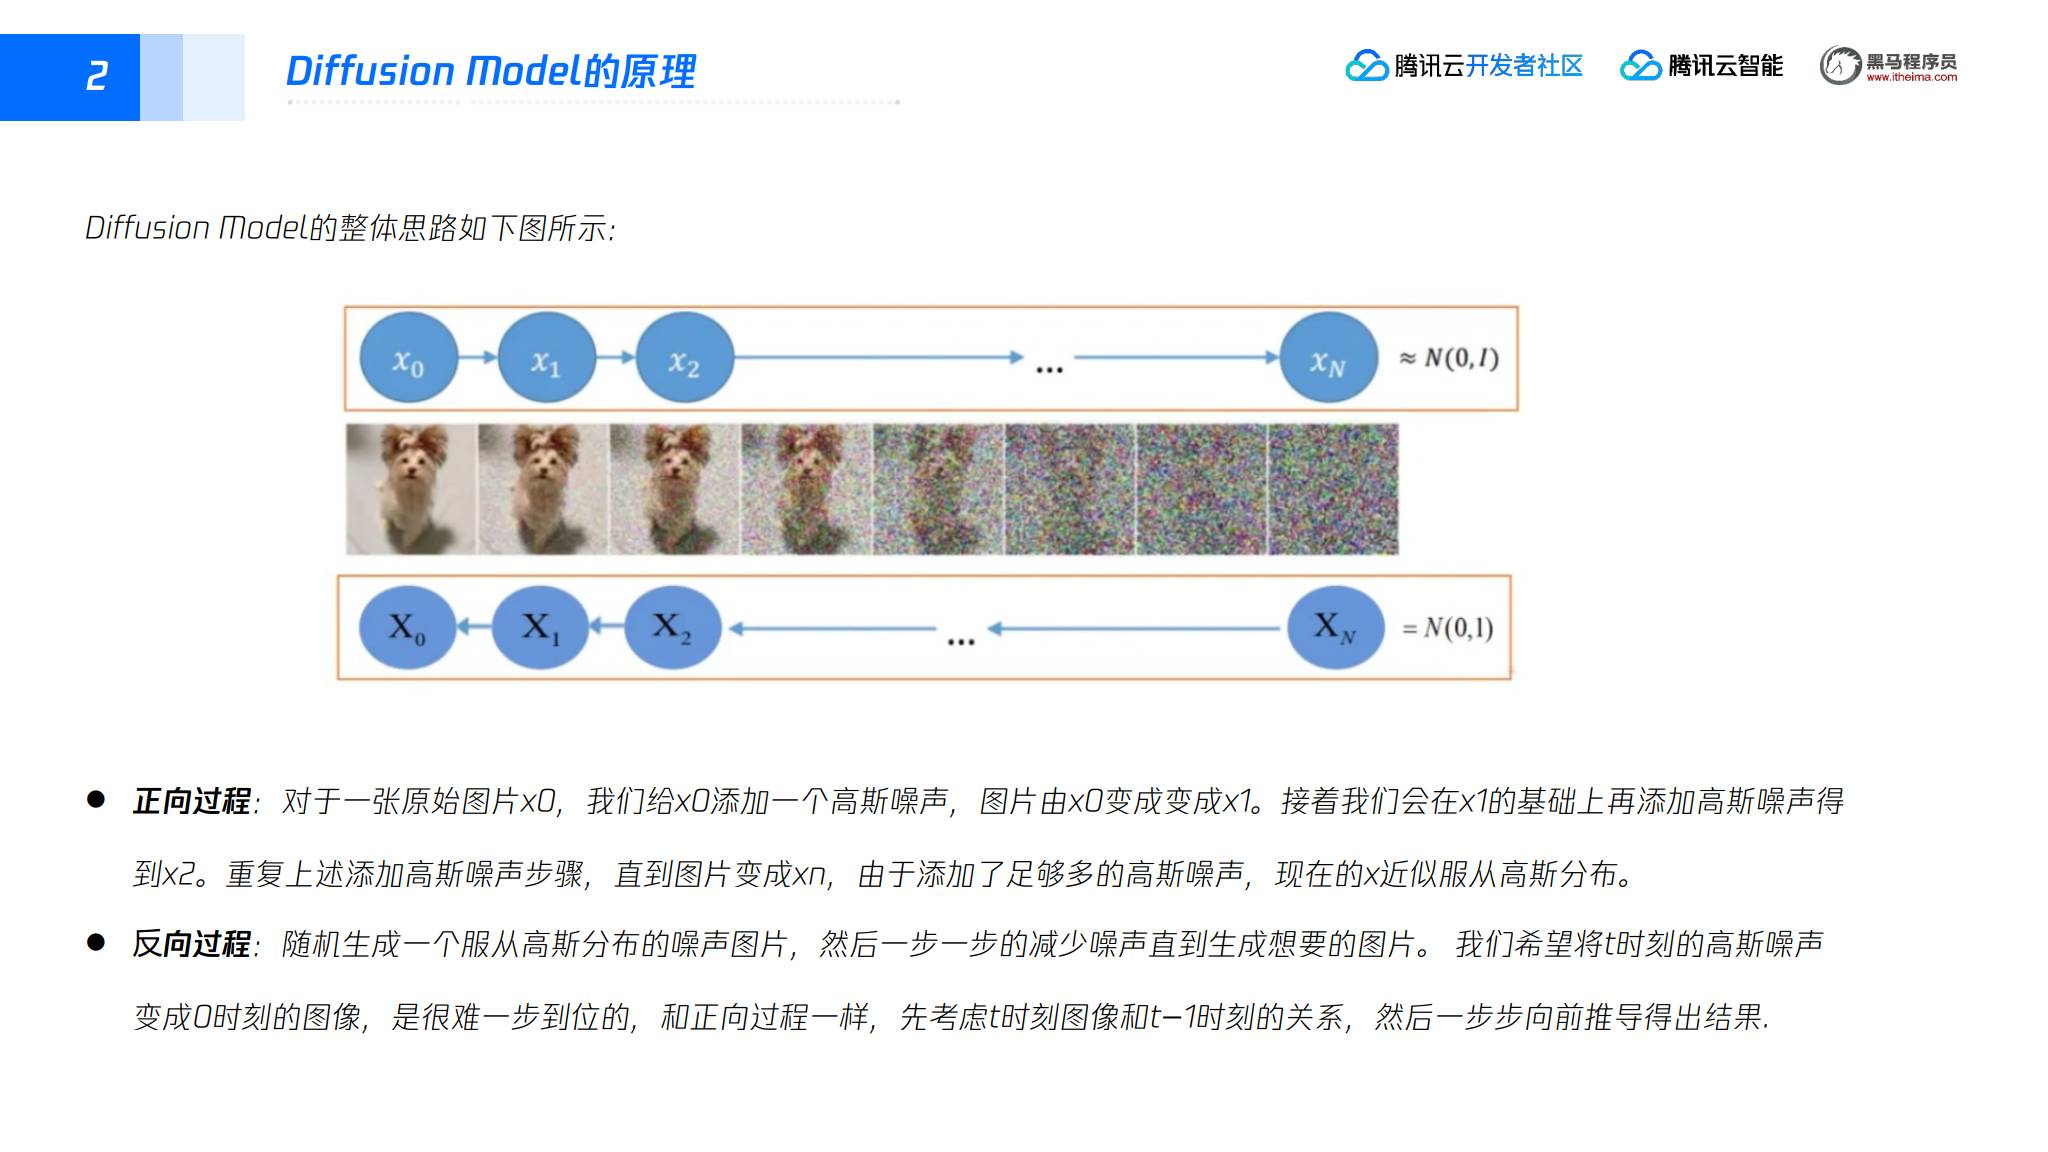

### 2. 为什么要在潜空间中扩散

标准扩散模型直接在像素空间中运算，需要处理大量高维数据。以三通道 `512×512` 图像为例，像素空间维度是 `3 × 512 × 512 = 786,432`。

Stable Diffusion 先使用 VAE 把图像压缩到低维潜空间，再在潜空间执行扩散和去噪，最后将结果解码回像素空间。由于潜空间比原始图像空间小很多，数据处理量和硬件要求都能降低，生成速度也得到提升。

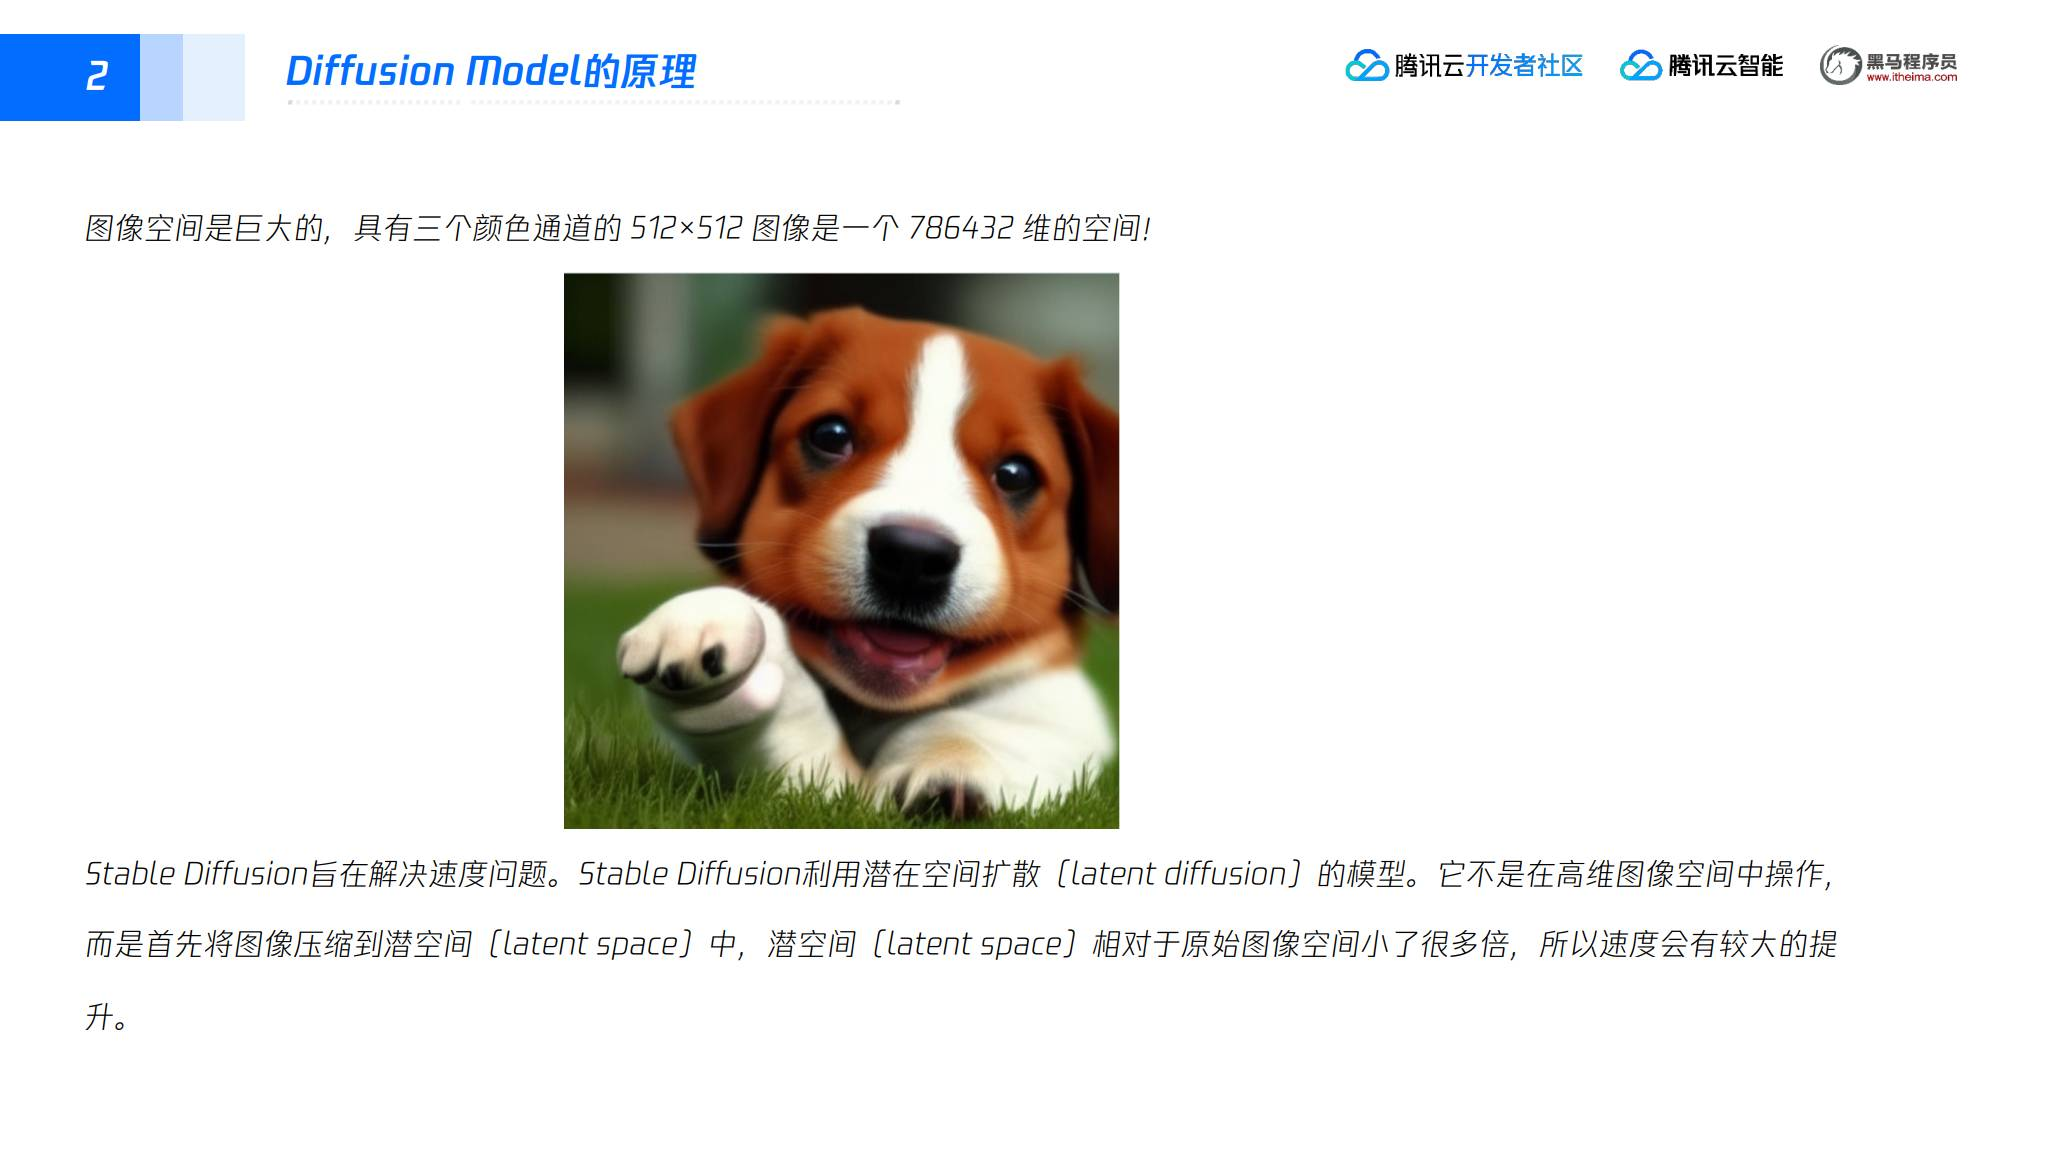

### 3. Stable Diffusion 的三部分架构

Stable Diffusion 不是单一模型，而是由三个结构协同完成生成：

| 结构 | 作用 | 输入与输出 |
| --- | --- | --- |
| **CLIP Text Encoder** | 解析提示词 | 输入文本 prompt，输出文本 token 的嵌入向量；讲义给出的向量维度为 768 |
| **Diffusion Model** | 在潜空间中预测并去除噪声 | 输入文本嵌入和噪声组成的初始多维数组，由 U-Net 与 Scheduler 完成处理 |
| **VAE** | 压缩和恢复图像 | 输入处理后的 `(4, 64, 64)` 信息矩阵，输出 `(3, 512, 512)` 的 RGB 图像 |

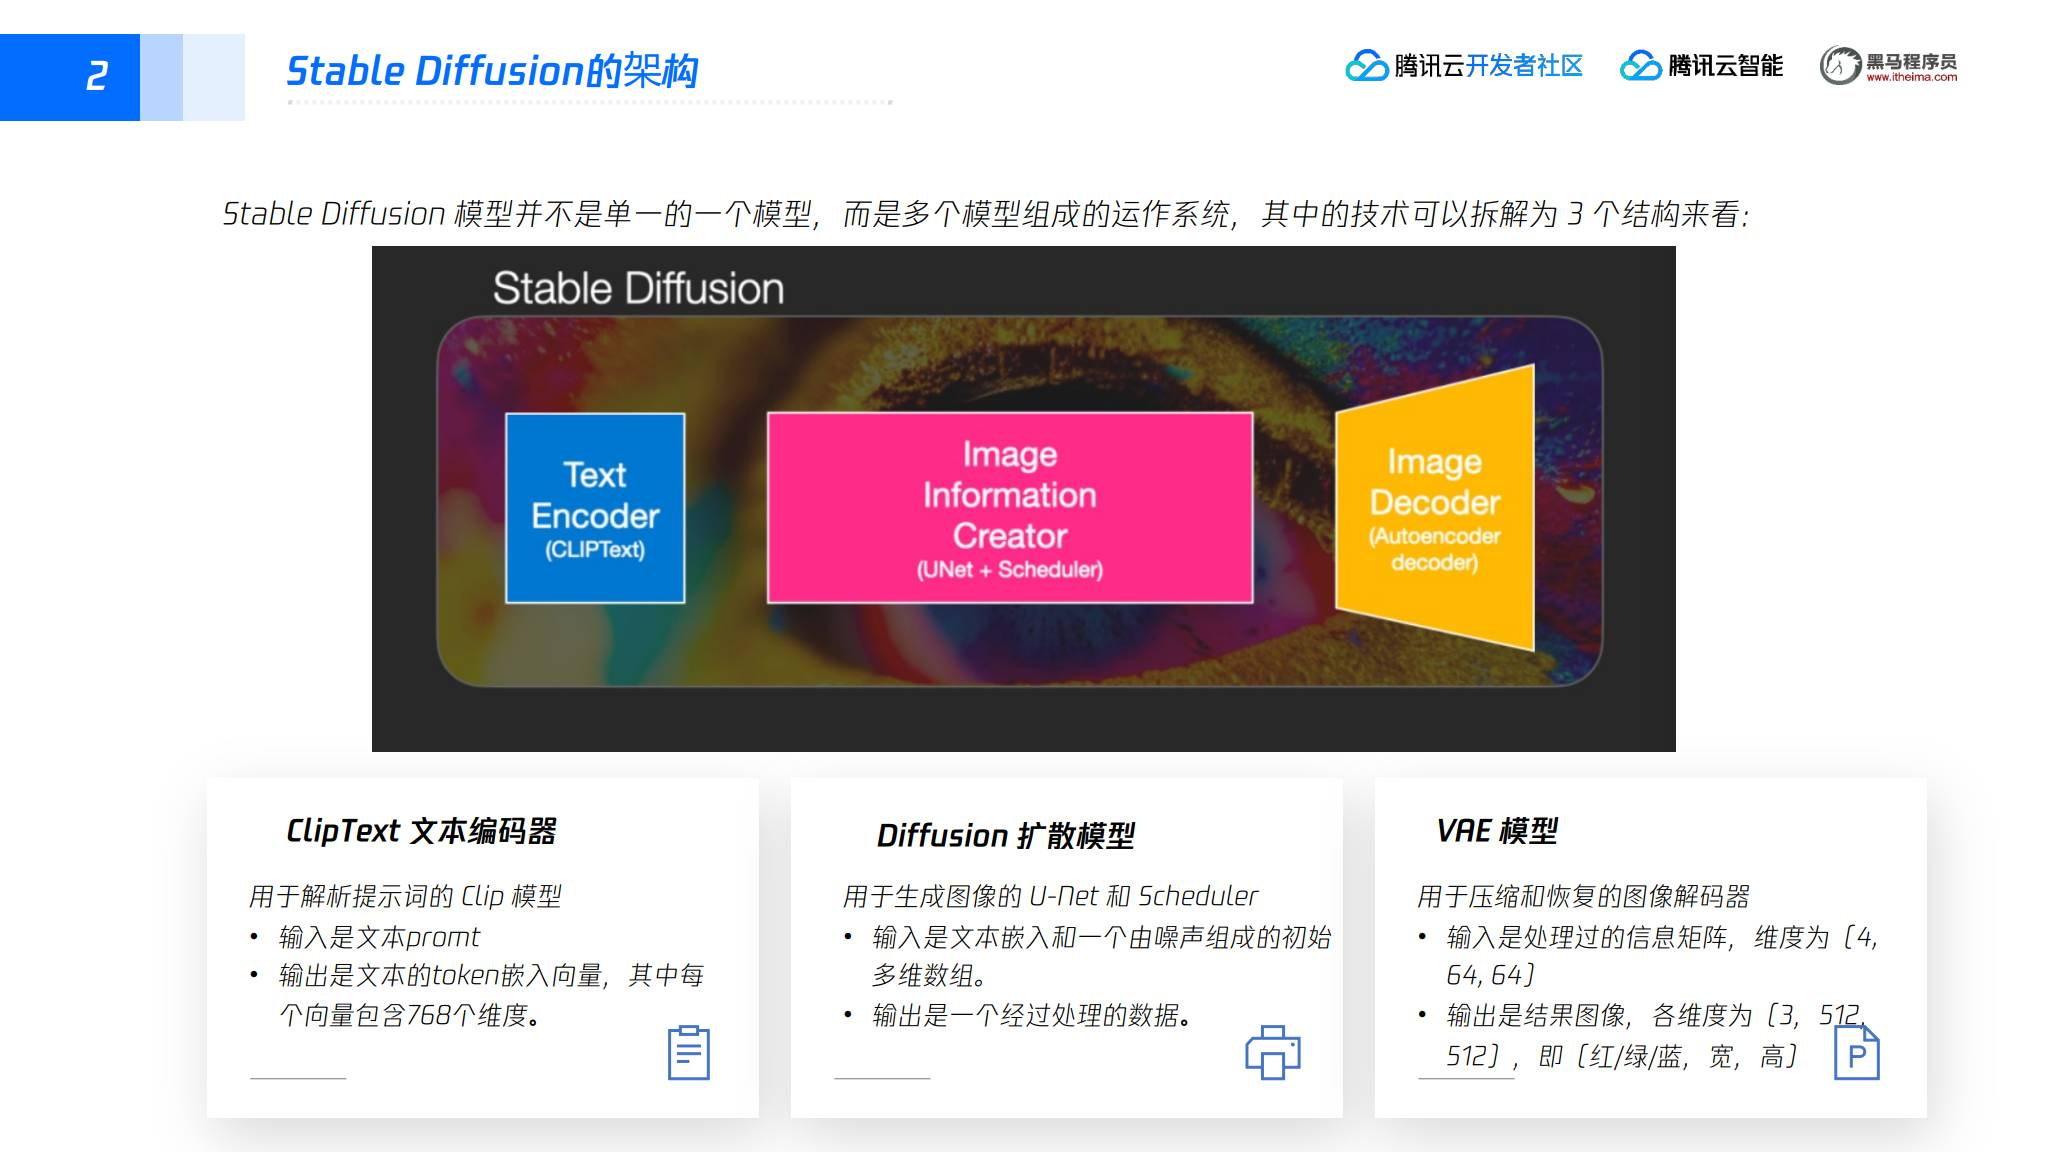

### 4. CLIP 文本编码器

CLIP 是 OpenAI 提出的多模态神经网络，通过自然语言监督学习视觉概念。在 Stable Diffusion 中，CLIP 的职责是提取提示词的文本特征，并把这些特征传给图像生成模块，使模型理解输入文本，从而实现文本控制图像生成。

讲义描述的训练过程是：

1. 训练图像 CNN 和文本 Transformer，使两者能够预测图像 caption；
2. 对一个 batch 中的 N 个图文对提取图像表征 `I₁...Iₙ` 和文本表征 `T₁...Tₙ`；
3. 将 `(Iⱼ, Tⱼ)` 作为正样本，将 `(Iⱼ, Tₖ)`（`j ≠ k`）作为负样本；
4. 最大化正样本的余弦相似度，最小化负样本的余弦相似度。

完成预训练后，CLIP 还可以做 Zero-Shot Transfer。讲义强调，在图像生成过程中 CLIP 的参数被冻结，不会随每次出图发生变化。

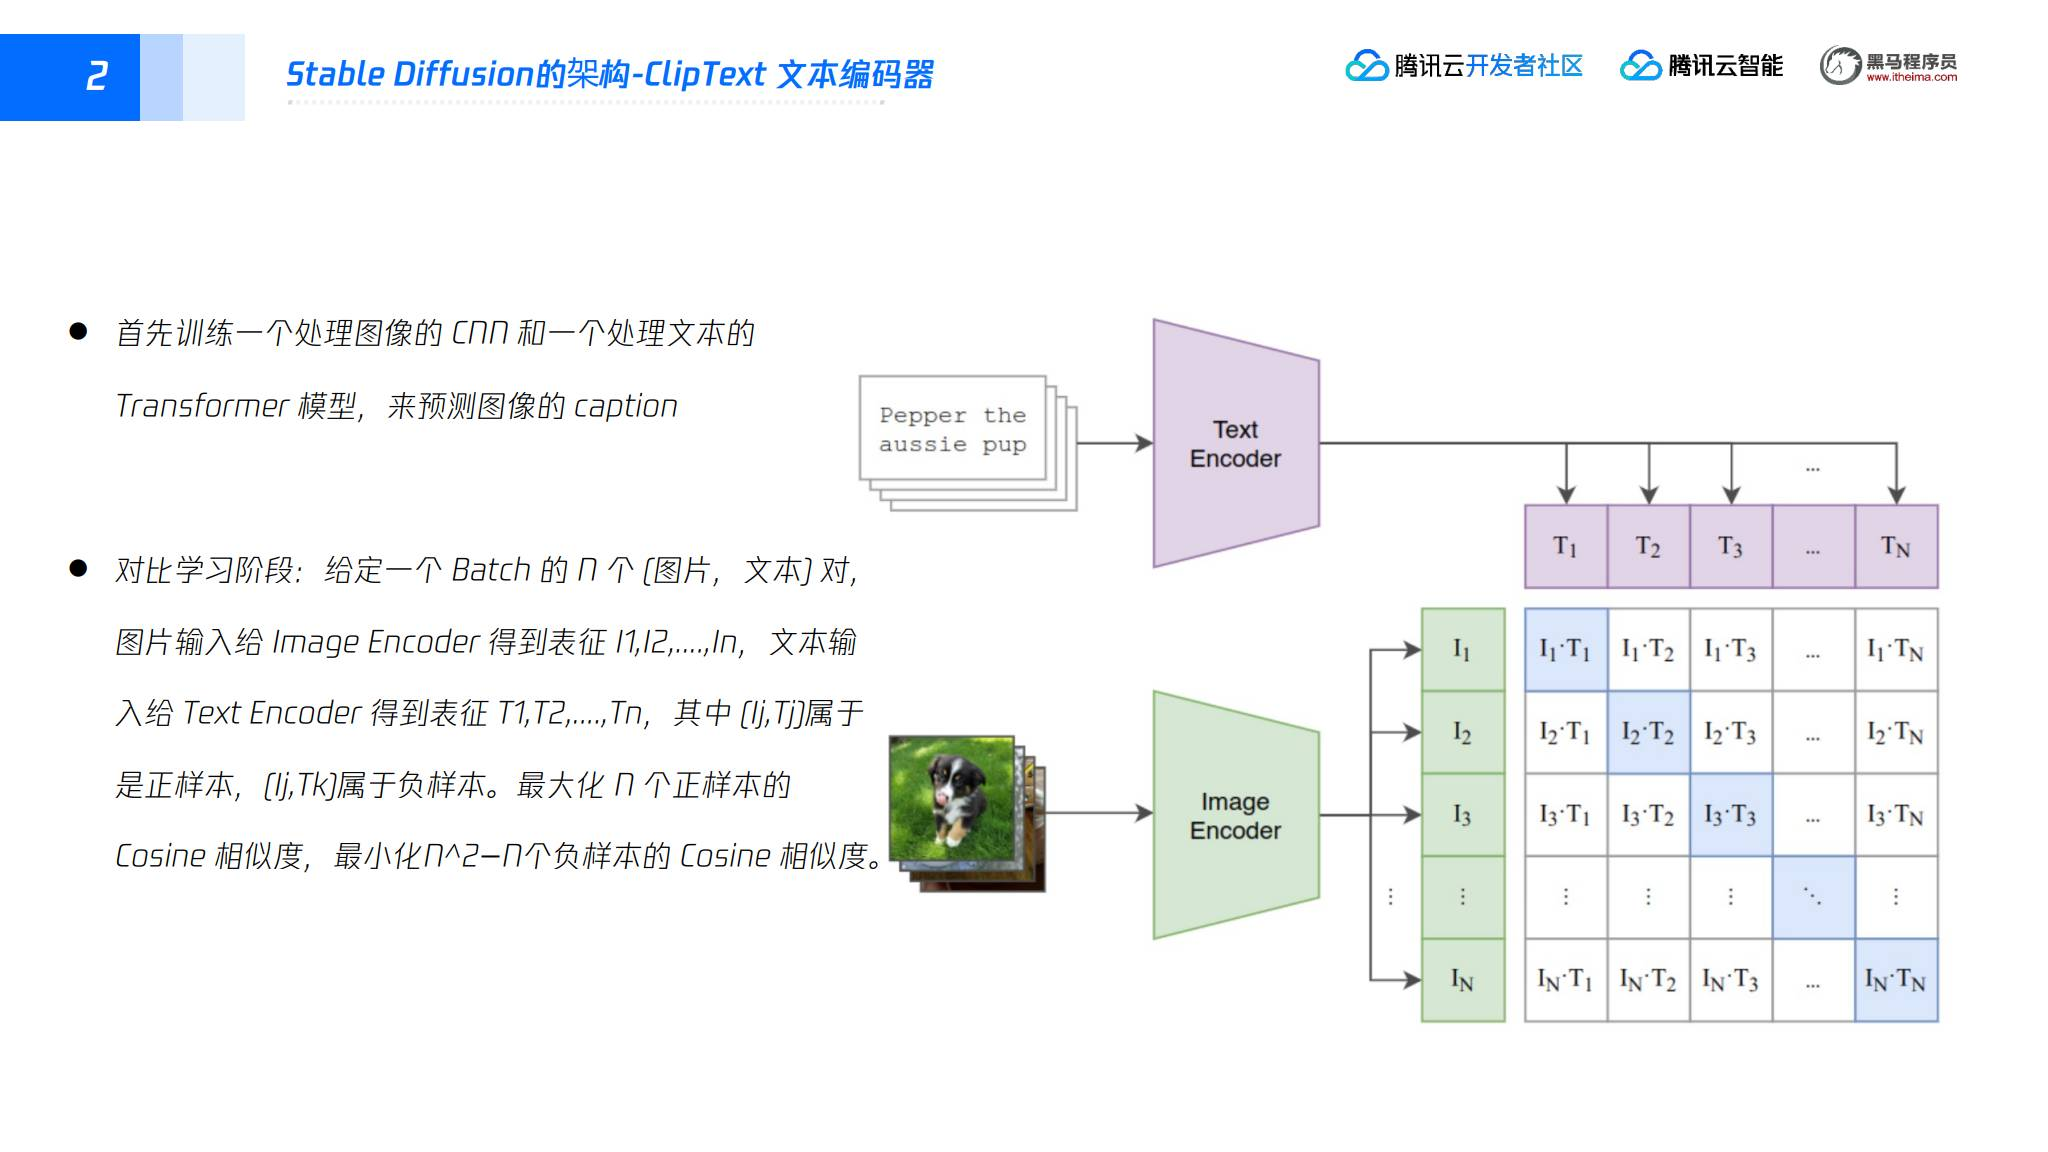

### 5. U-Net 与 Scheduler

- **U-Net**：最初用于生物医学图像分割，因为网络结构类似字母 U 而得名。在扩散模型中，U-Net 提取和解构训练图像的特征，并预测当前时间步需要去除的噪声，帮助模型得到更准确、多样的结果。
- **Scheduler**：定义加噪和降噪过程采用的算法，包括降噪步骤、随机性和去噪样本的查找方式，因此也被称为采样算法。在 WebUI 中可以根据图像类型和使用的模型选择不同的采样器。

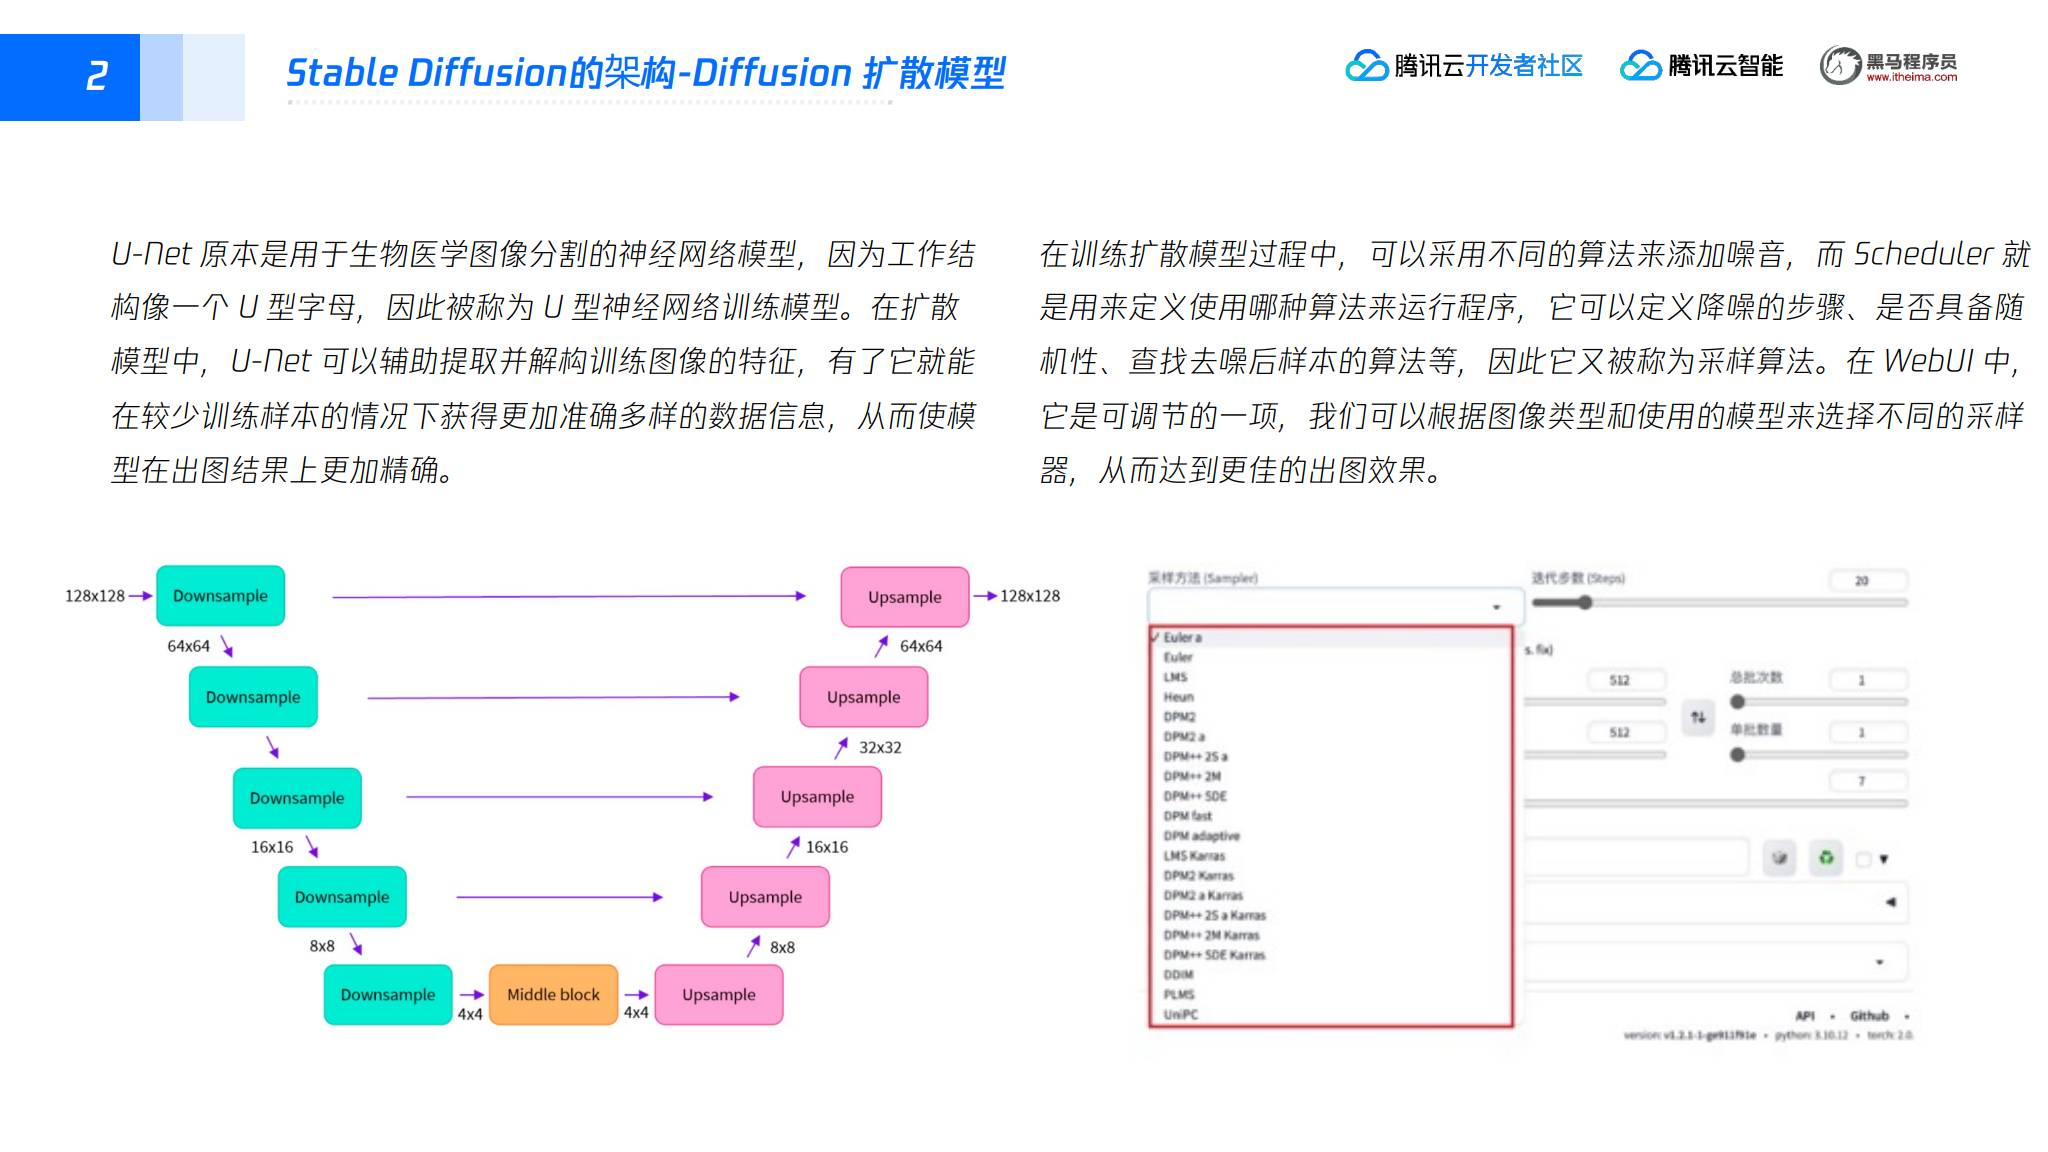

### 6. VAE 解码器

VAE（Variational Auto Encoder，变分自动编码器）负责在像素空间与潜空间之间进行压缩和恢复：

- 编码器把高维图像映射到低维潜空间；
- 解码器把潜在数据表示转换回原始图像；
- 在潜在扩散模型的推理阶段，主要使用 VAE 的解码器把最终潜变量还原为像素图像。

讲义强调，VAE 解码是从潜空间得到最终像素图像的最后一步，整个解码过程运行一次即可生成最终结果。

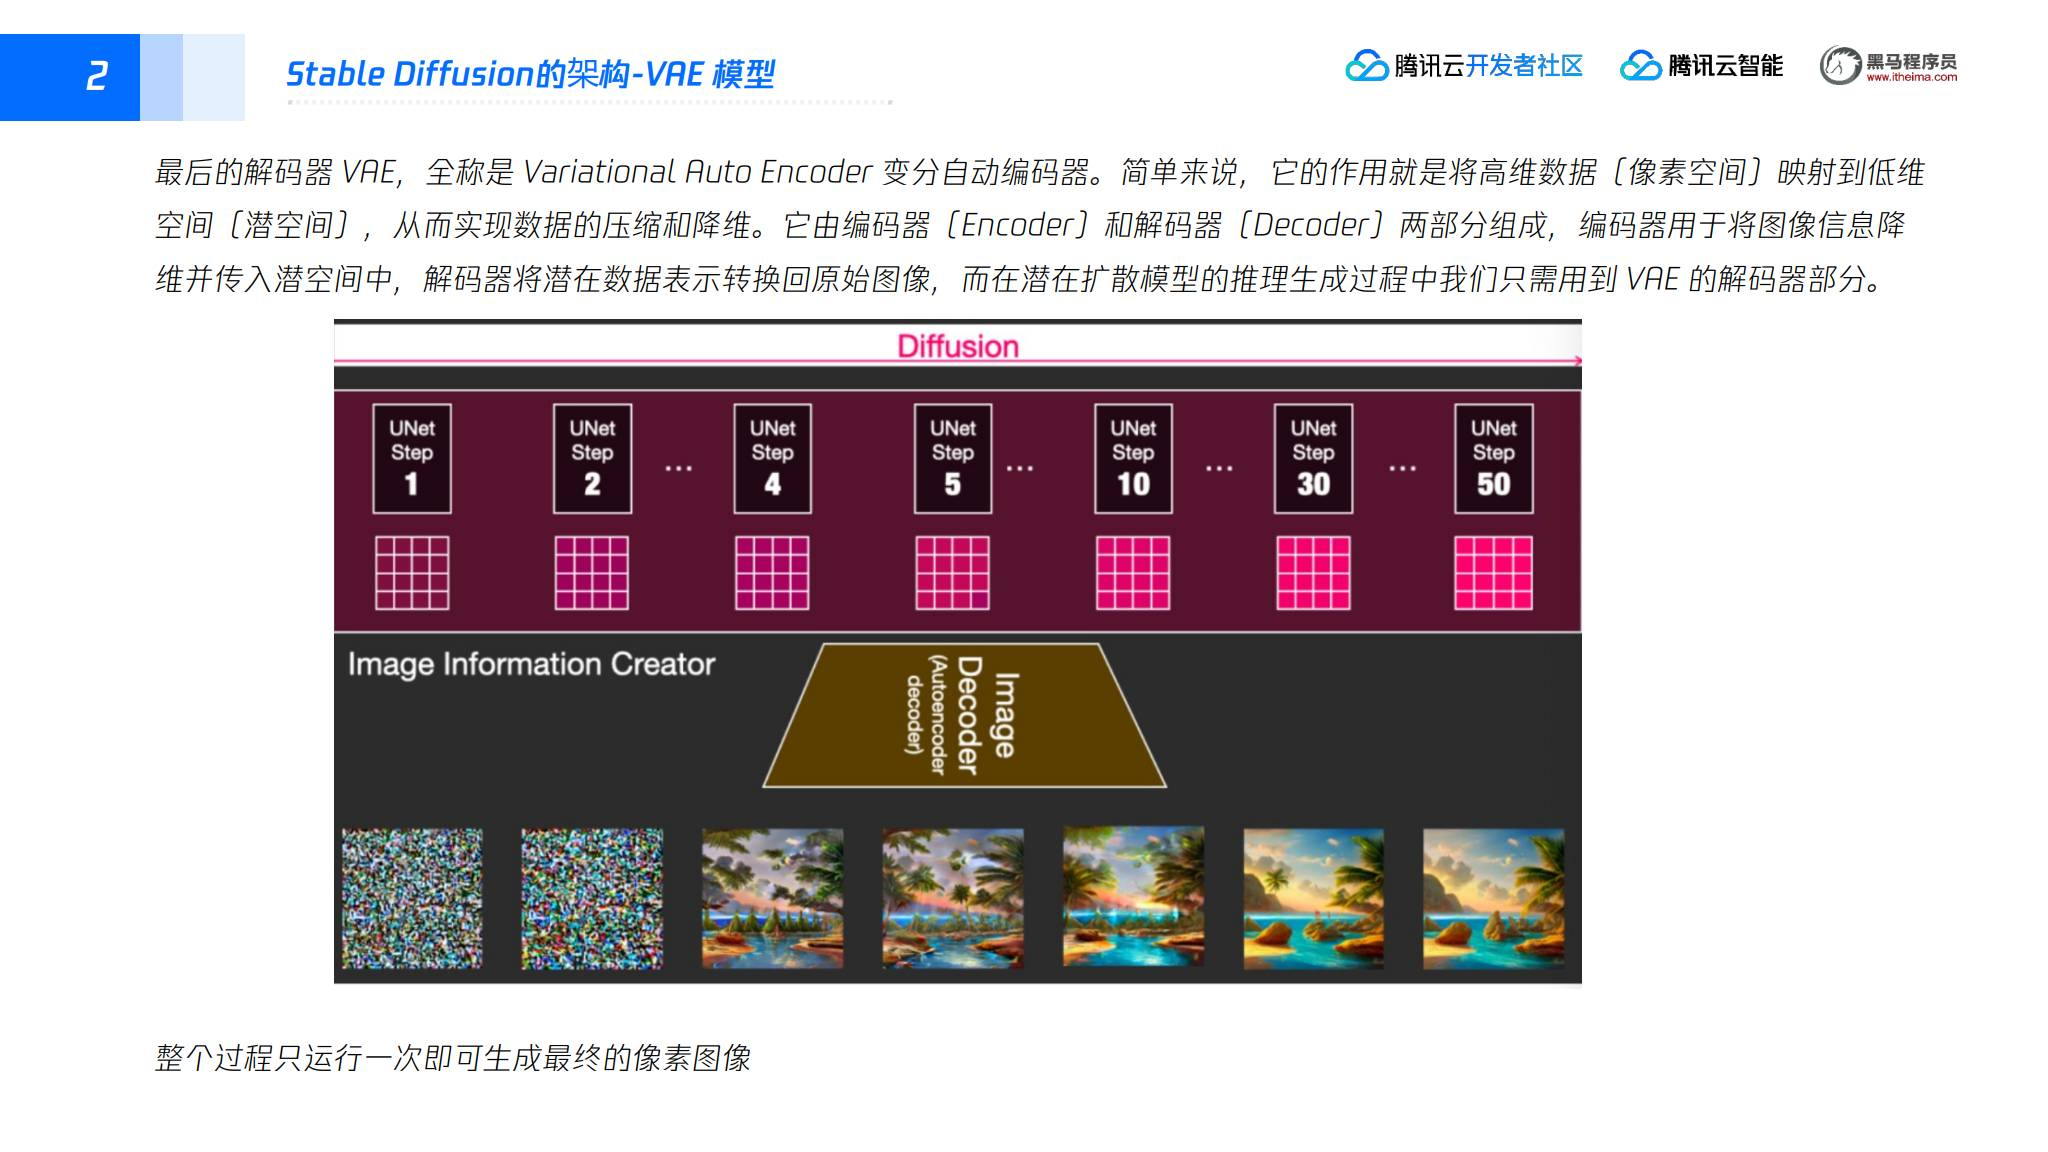

## 三、Stable Diffusion 的文生图流程

从文本生成图像时，Stable Diffusion 按以下步骤运行：

1. 在潜空间中生成随机张量。可以通过随机数生成器的 **seed** 控制这个张量；seed 相同时，可以得到相同的初始随机张量。
2. U-Net 接收潜在噪声图像和文本提示，预测潜空间中的噪声，张量形状示例为 `4×64×64`。
3. 从潜在图像中减去预测出的潜在噪声，得到新的潜在图像。
4. 重复步骤 2 和 3 多次，例如进行 20 次采样。
5. 采样结束后，VAE 解码器把潜在图像转换回像素空间，得到最终图像。

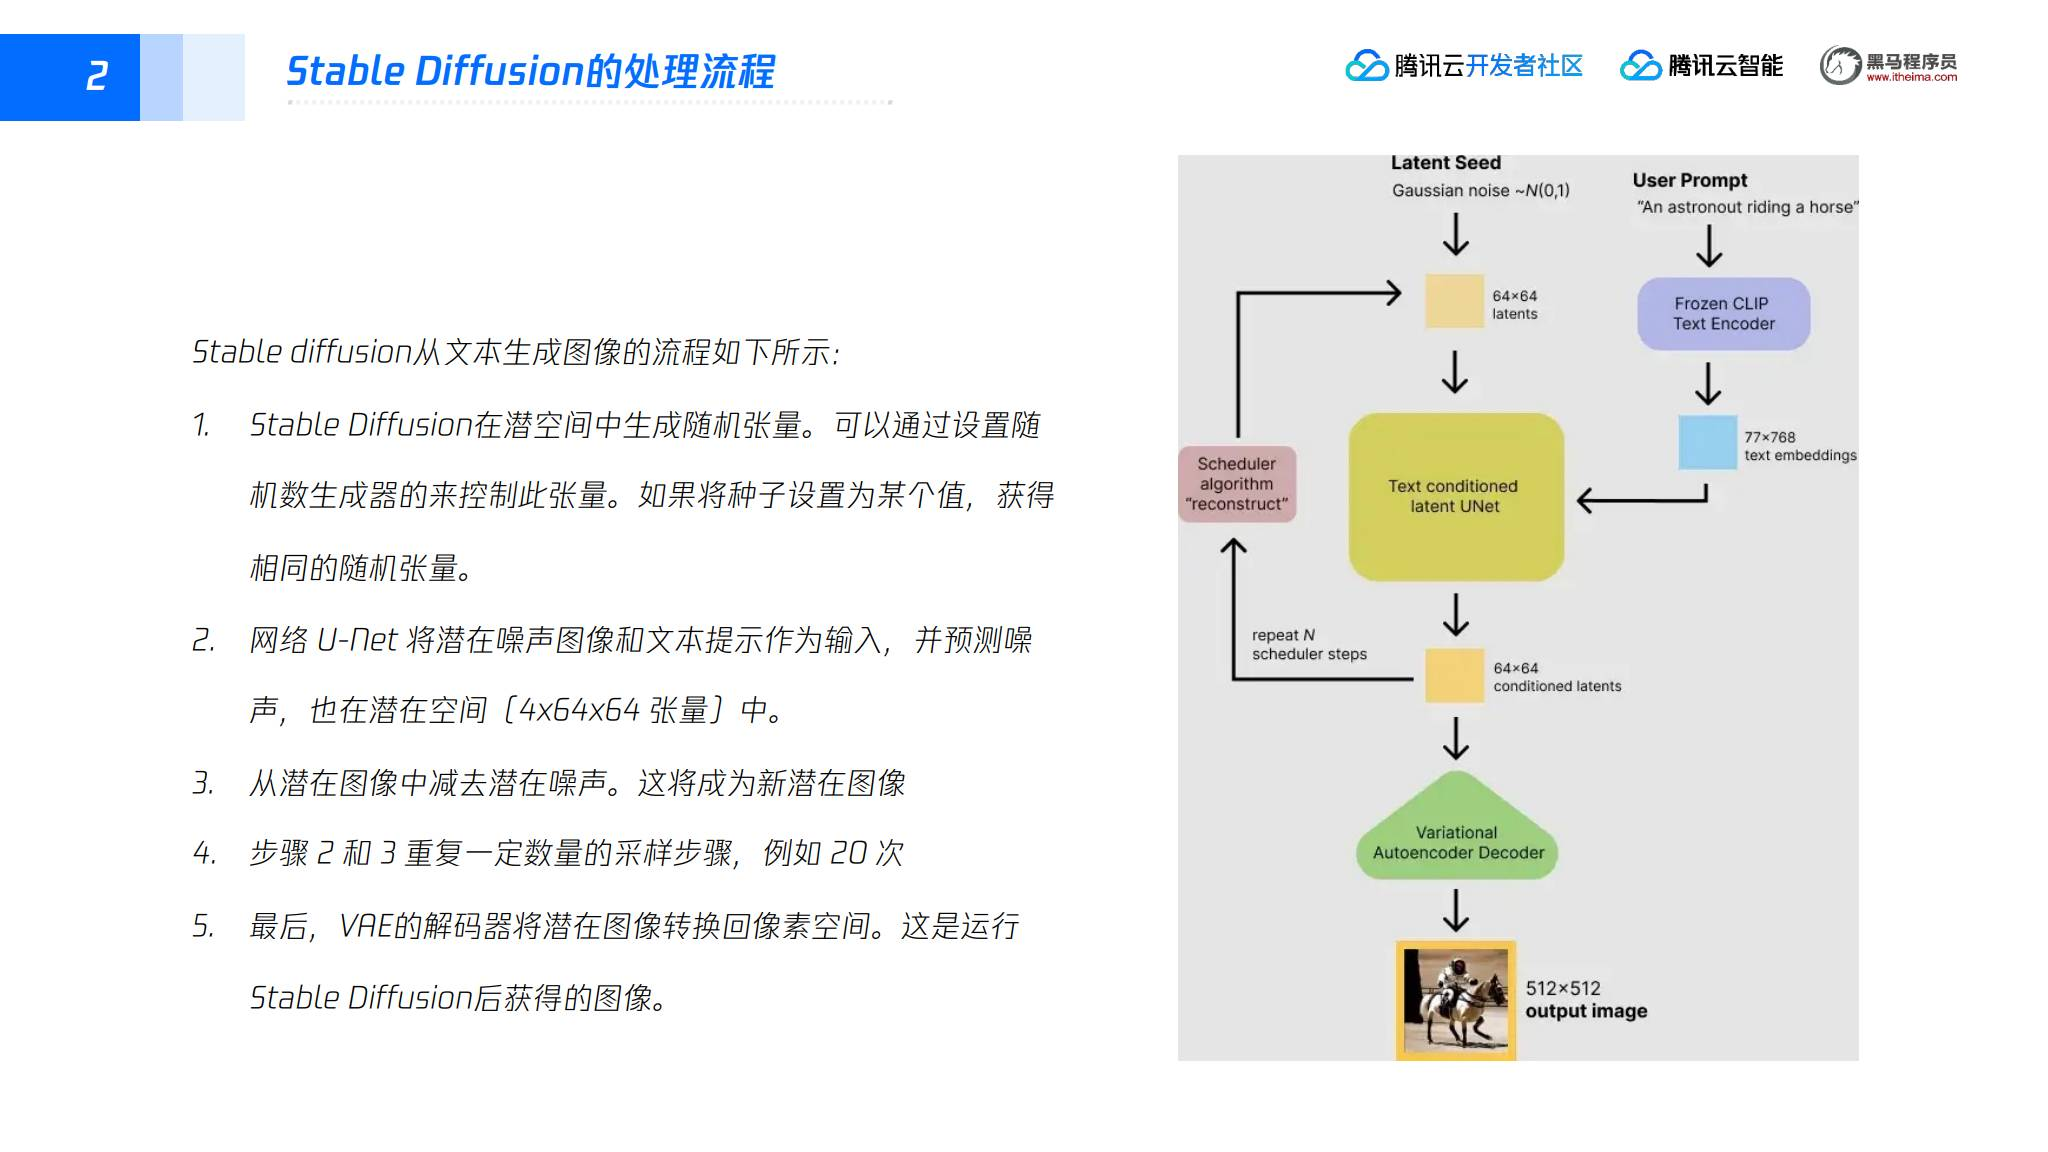

## 四、Stable Diffusion 的应用场景

### 1. 文生图

把输入的文字提示转换成图像，使文字描述变成可视化内容。提示词通常决定主体、场景、风格和画面细节。

### 2. 图生图

同时依赖输入图片和提示词进行二次创作，可以减少纯随机生成带来的不确定性，更好地满足构图或内容要求。讲义还提到，图生图可以生成带有深度信息的图像。

### 3. 图像修复

替换或填充图像指定区域的纹理、像素，使修改区域与周围内容自然融合，从而完成和谐的修复效果。

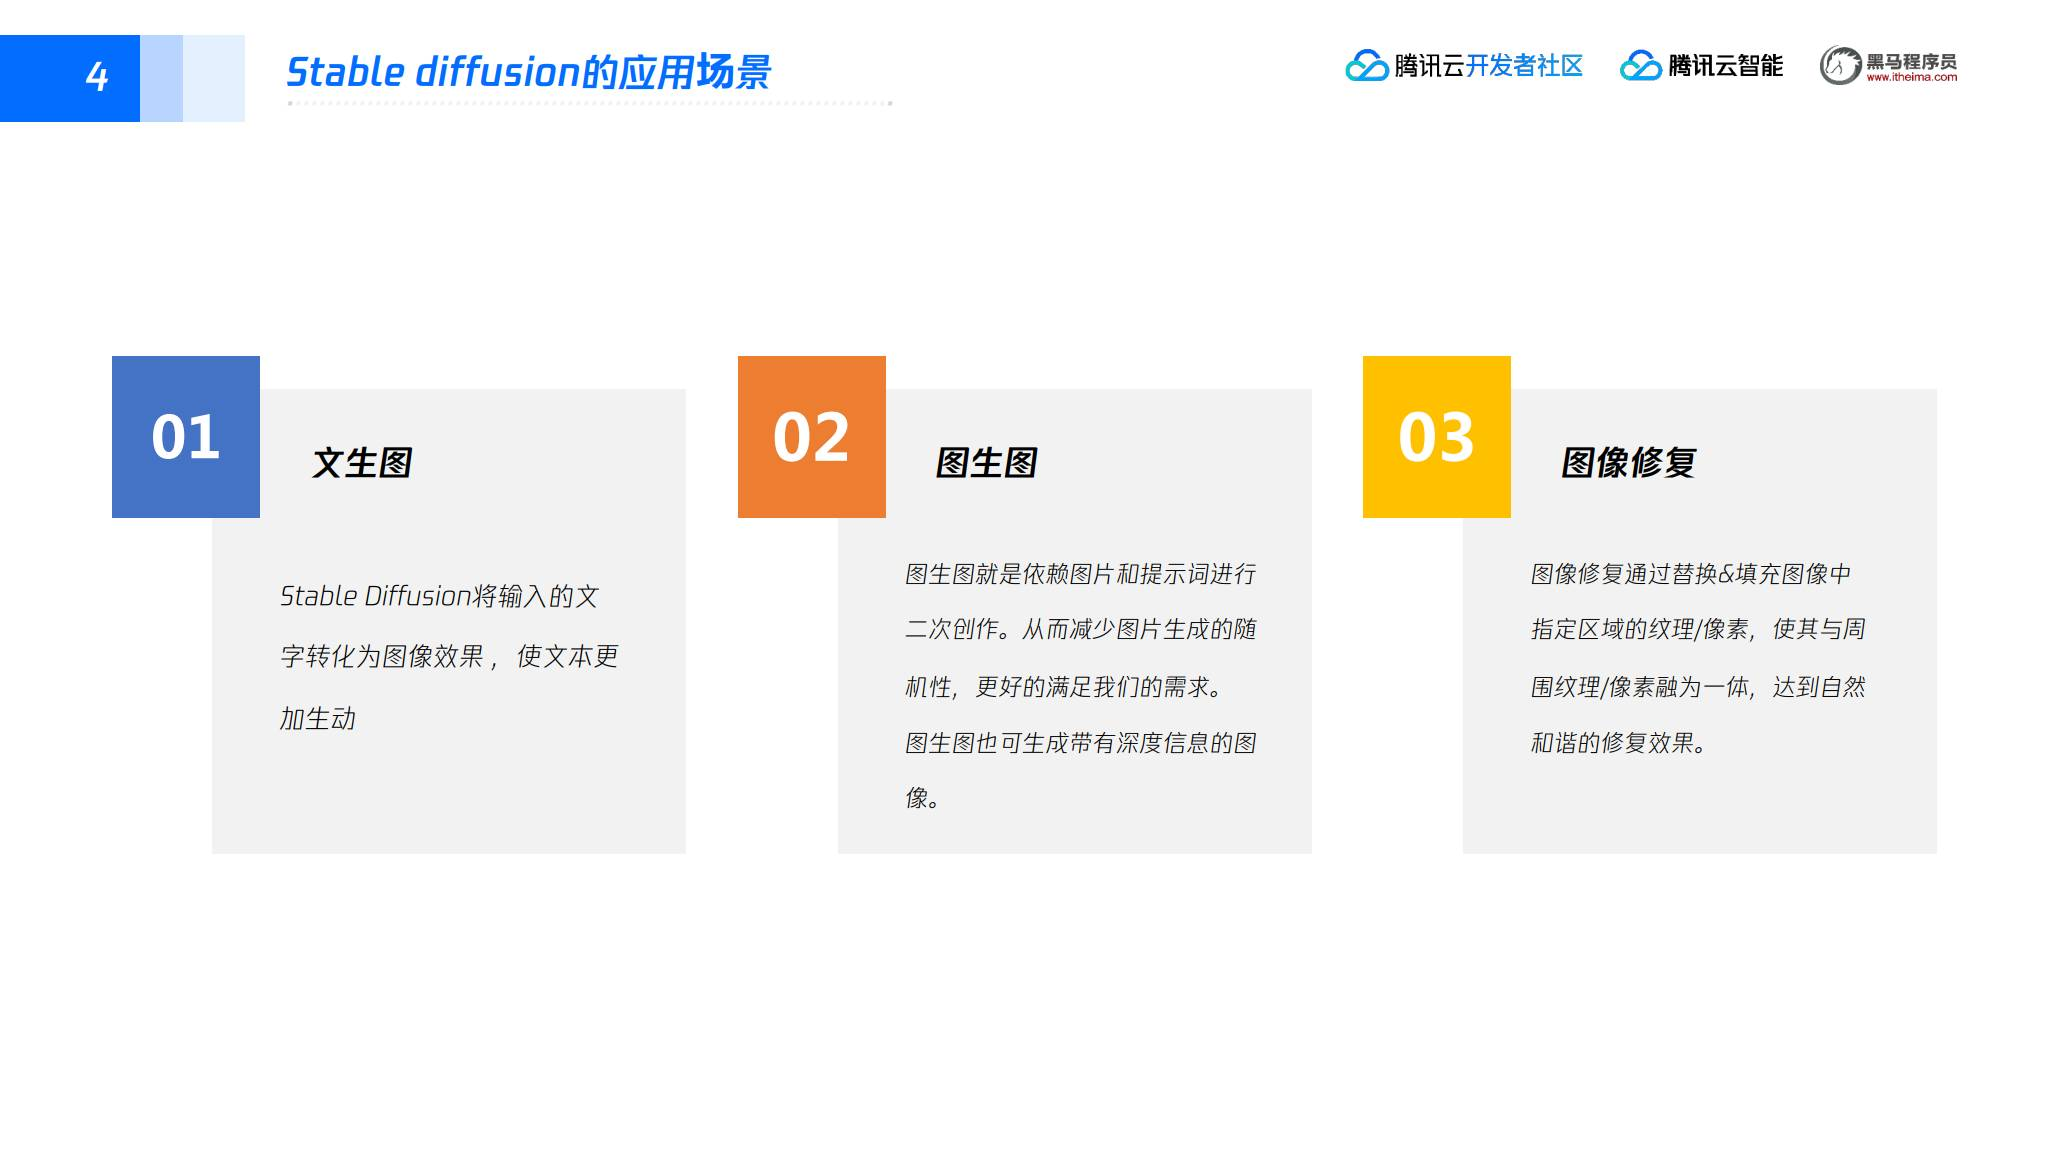

## 五、本篇要点

1. Stable Diffusion 是基于潜在扩散模型的开源图像生成系统，WebUI 是控制它出图的网页界面。
2. 它把高维图像压缩到潜空间，在潜空间完成扩散运算，再通过 VAE 解码回像素空间。
3. CLIP 负责理解文本提示，U-Net 预测噪声，Scheduler 决定采样和降噪策略，VAE 负责最终图像恢复。
4. 文生图的核心循环是“预测噪声—减去噪声—重复采样”，seed 用于控制初始随机状态。
5. Stable Diffusion 的主要应用包括文生图、图生图和图像修复。